In [1]:
import pandas as pd

path = "./data/"
df = pd.read_csv(path+"BTCUSDT-last.csv", sep='|')
df = df.rename(columns={'1502942400': 'timestamp', '4261.48': 'open', '4261.48.1': 'high', '4261.48.2': 'low', '4261.48.3': 'close', '1.775183': 'btc_volume_sell', '320.390851': 'usd_volume_buy', '0.075183': 'btc_volume_buy', '7564.906851': 'usd_volume_sell', '3': 'activity'})

df

,timestamp,open,high,low,close,btc_volume_sell,usd_volume_buy,btc_volume_buy,usd_volume_sell,activity
0,1502942460,4261.48,4261.48,4261.48,4261.48,0.000000,0.000000e+00,0.000000,0.000000e+00,0
1,1502942520,4280.56,4280.56,4280.56,4280.56,0.261074,1.117543e+03,0.261074,1.117543e+03,2
2,1502942580,4261.48,4261.48,4261.48,4261.48,0.012008,5.117185e+01,0.012008,5.117185e+01,3
3,1502942640,4261.48,4261.48,4261.48,4261.48,0.140796,5.999993e+02,0.140796,5.999993e+02,1
4,1502942700,4261.48,4261.48,4261.48,4261.48,0.000000,0.000000e+00,0.000000,0.000000e+00,0
...,...,...,...,...,...,...,...,...,...,...
4310479,1762084860,111244.68,111244.68,111112.04,111115.80,34.693590,5.436972e+05,4.891980,3.855896e+06,7258
4310480,1762084920,111115.80,111168.80,111111.00,111116.46,9.870260,8.407340e+05,7.565000,1.096928e+06,3224
4310481,1762084980,111116.45,111154.06,111098.48,111138.32,11.443350,8.327354e+05,7.493850,1.271624e+06,4728
4310482,1762085040,111138.33,111192.01,111138.33,111192.00,4.806260,2.443595e+05,2.198210,5.342619e+05,1575


<Axes: title={'center': 'BTCUSDT Close Prices'}>

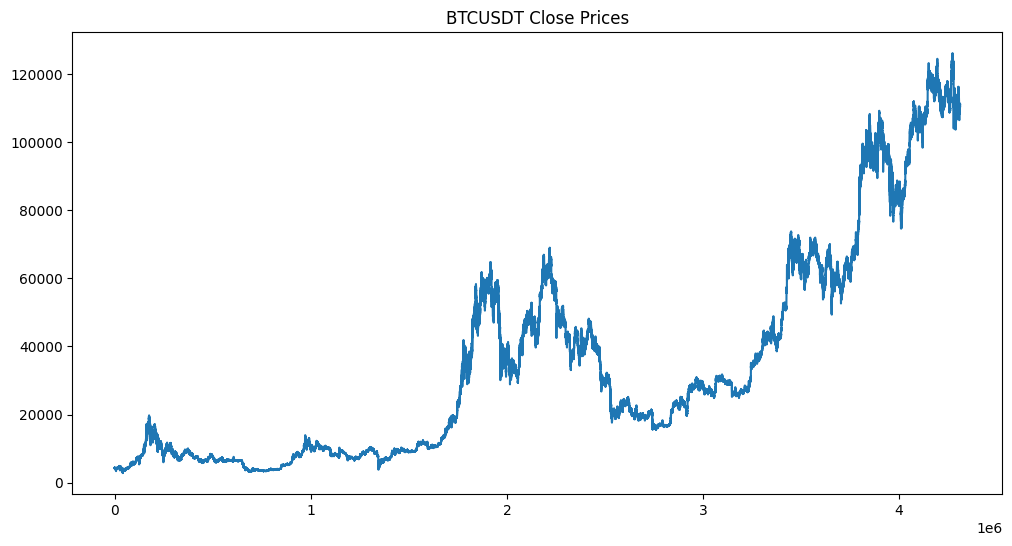

In [2]:
main_folder = 'backtest_results'
data_combination_folders = ['price_only', 'sentiment_only', 'technicals_only', 'full_dataset']
csv_filenames_bull_market = ['threshold_backtest_trades-1.csv', 'risk_based_backtest_trades-1.csv', 'momentum_backtest_trades-1.csv']
csv_filenames_Sideways_market = ['threshold_backtest_trades-2.csv', 'risk_based_backtest_trades-2.csv', 'momentum_backtest_trades-2.csv']

df['timestamp'] = pd.to_datetime(df['timestamp'], unit='s')
df['close'].plot(title='BTCUSDT Close Prices', figsize=(12, 6))

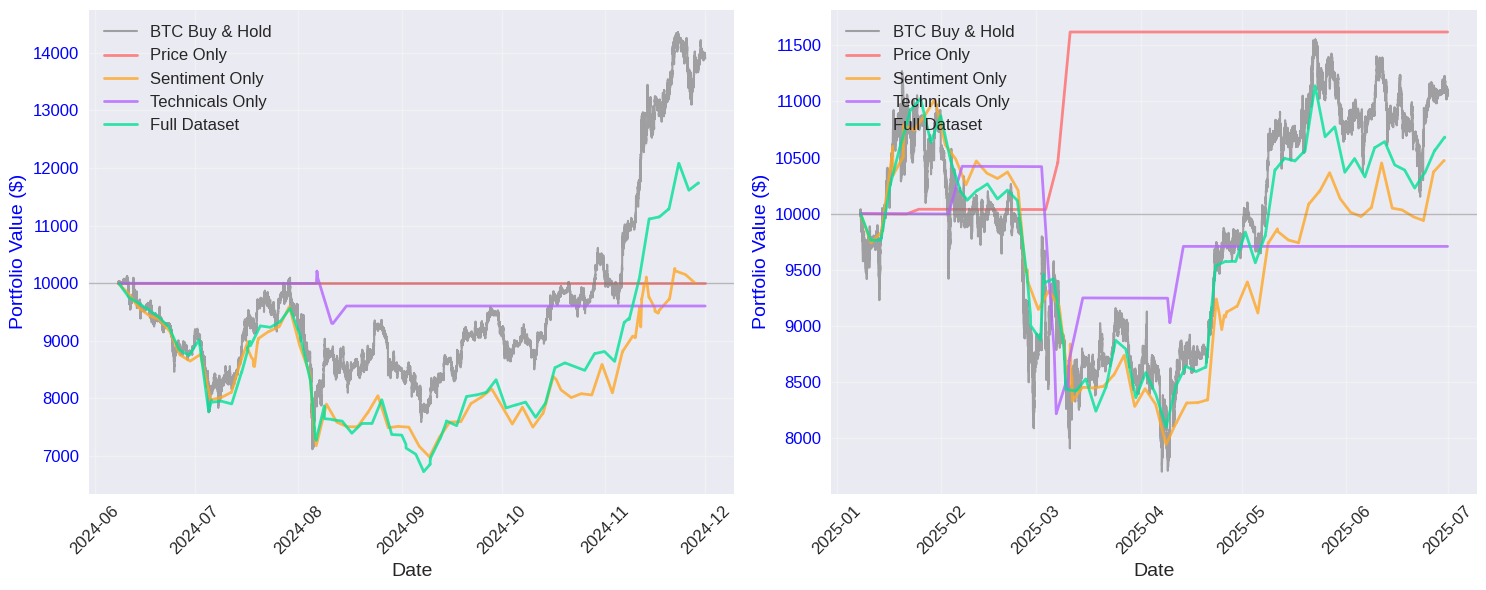

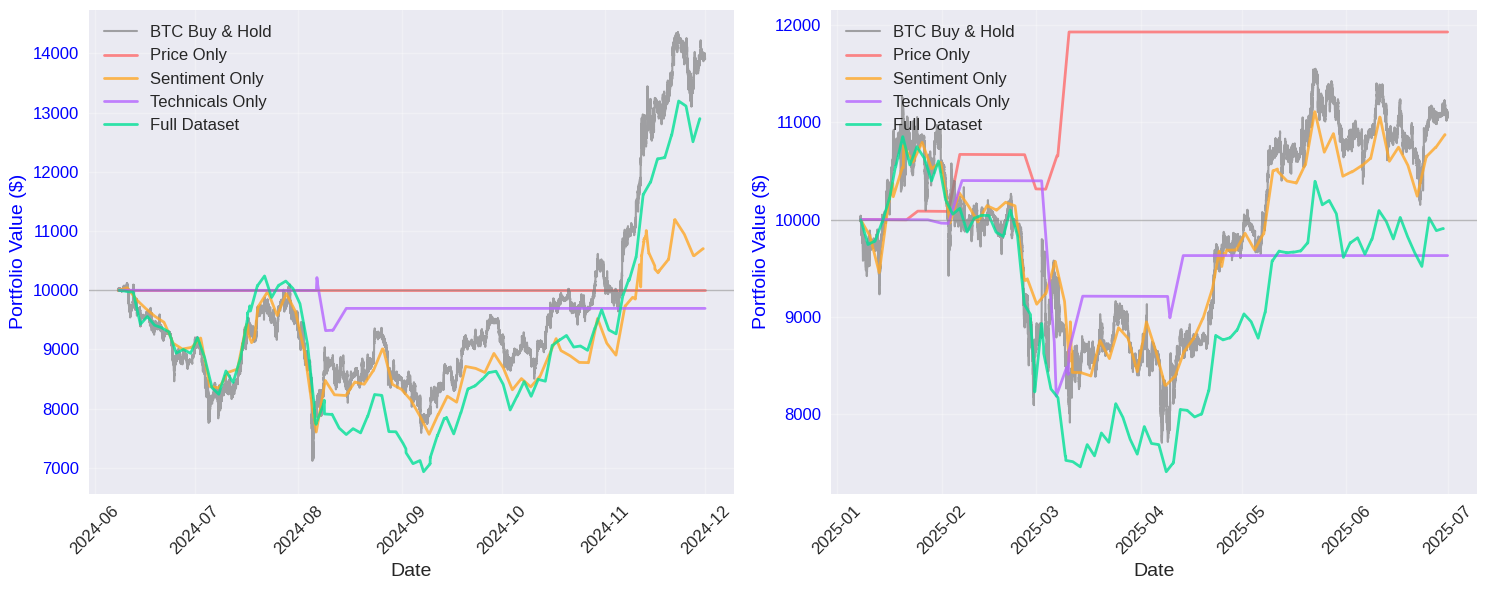

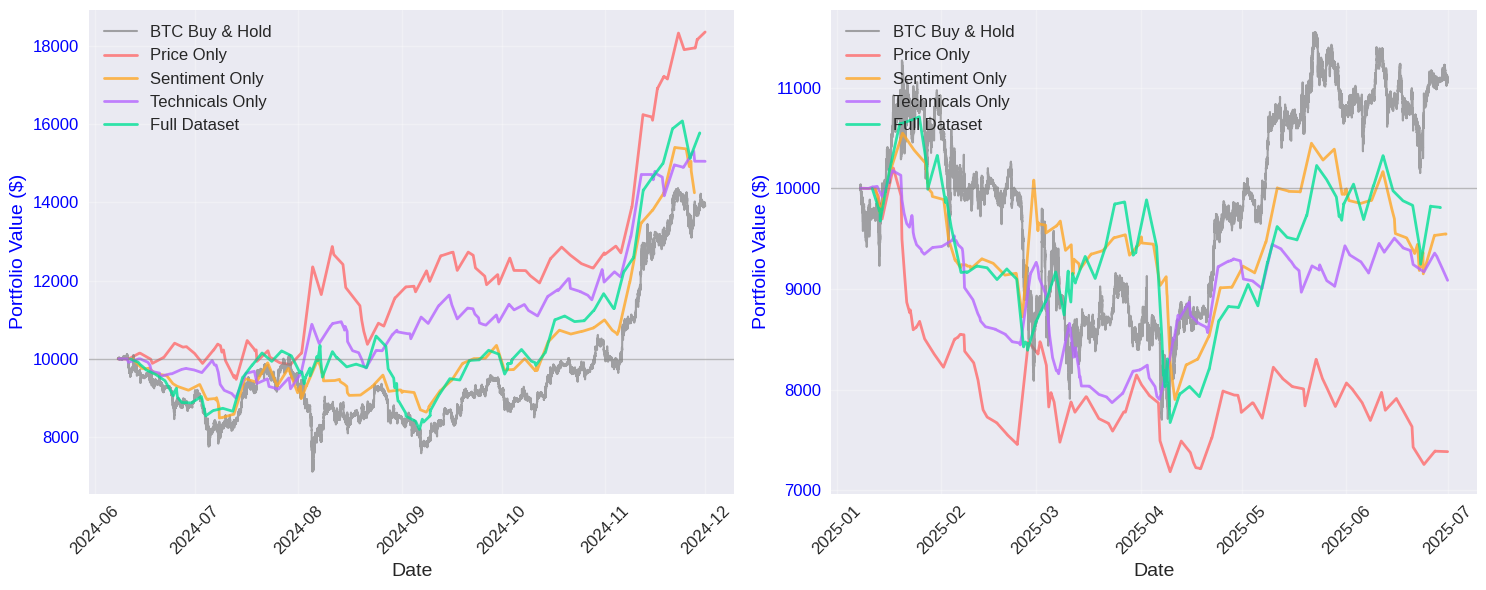

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import os

import matplotlib.pyplot as plt
import numpy as np
import os

# Set up the plotting style
plt.style.use('seaborn-v0_8')

# Define strategy names and their corresponding file patterns
strategies = {
    'threshold': 'Threshold Strategy',
    'risk_based': 'Risk-Based Strategy', 
    'momentum': 'Momentum Strategy'
}

# Define market conditions
markets = {
    'bull': {'files': csv_filenames_bull_market, 'label': 'Bull Market', 'col': 0},
    'Sideways': {'files': csv_filenames_Sideways_market, 'label': 'Sideways Market', 'col': 1}
}

# Color scheme for different data combinations
colors = {
    'price_only': '#FF6B6B',      # Coral red - keep
    'sentiment_only': '#FFA726',  # Warm orange - much better visibility
    'technicals_only': '#B565FF',  # Light purple - good contrast
    'full_dataset': '#00E096'     # Bright teal - pops well
}

# Process each strategy separately
for strategy_idx, (strategy_key, strategy_name) in enumerate(strategies.items()):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    #fig.suptitle(f'{strategy_name} Performance: Bull Market vs Sideways Market', fontsize=16, fontweight='bold')
    
    for market_key, market_info in markets.items():
        ax = axes[market_info['col']]
        
        # Find the correct filename for this strategy
        if strategy_key == 'threshold':
            filename_pattern = 'threshold_backtest_trades'
        elif strategy_key == 'risk_based':
            filename_pattern = 'risk_based_backtest_trades'
        else:  # momentum
            filename_pattern = 'momentum_backtest_trades'
        
        # Determine the file suffix based on market
        file_suffix = '-1.csv' if market_key == 'bull' else '-2.csv'
        filename = f"{filename_pattern}{file_suffix}"
        
        # Create secondary y-axis for BTC price
        #ax2 = ax.twinx()
        
        # Plot BTC price on secondary axis (only once per subplot)
        btc_subset = df.copy()
        
        # Plot data for each data combination
        first_file_processed = False
        for folder in data_combination_folders:
            file_path = os.path.join(main_folder, folder, filename)
            
            try:
                # Read the CSV file
                backtest_df = pd.read_csv(file_path)
                
                # Convert datetime column
                backtest_df['datetime'] = pd.to_datetime(backtest_df['datetime'])
                
                # Plot portfolio value over time on primary axis
                ax.plot(backtest_df['datetime'], backtest_df['portfolio_value'], 
                       label=folder.replace('_', ' ').title(), 
                       color=colors[folder], linewidth=2, alpha=0.8)
                
                # Plot BTC price on secondary axis (only for first file to avoid duplicates)
                if not first_file_processed:
                    # Filter BTC data to match the backtest timeframe
                    start_time = backtest_df['datetime'].min()
                    end_time = backtest_df['datetime'].max()
                    btc_filtered = btc_subset[(btc_subset['timestamp'] >= start_time) & 
                                            (btc_subset['timestamp'] <= end_time)]
                    
                    if len(btc_filtered) > 0:
                        # Normalize BTC price to start at 10000 for comparison
                        btc_start_price = btc_filtered['close'].iloc[0]
                        btc_normalized = btc_filtered['close'] * (10000/btc_start_price)
                        
                        ax.plot(btc_filtered['timestamp'], btc_normalized, 
                               color='gray', linewidth=1.5, alpha=0.7, 
                               label='BTC Buy & Hold')
                    first_file_processed = True
                
                # Add final portfolio value annotation
                final_value = backtest_df['portfolio_value'].iloc[-1]
                initial_value = backtest_df['portfolio_value'].iloc[0]
                returns = ((final_value - initial_value) / initial_value) * 100
                
            except FileNotFoundError:
                print(f"Warning: File not found - {file_path}")
                continue
        
        # Customize subplot
        #ax.set_title(f"{market_info['label']}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Date', fontsize=14)
        ax.set_ylabel('Portfolio Value ($)', fontsize=14, color='blue')
        #ax2.set_ylabel('BTC Buy & Hold', fontsize=10, color='gray')
        ax.grid(True, alpha=0.3)
        
        # Reorder legend to put 'BTC Buy & Hold' first
        lines1, labels1 = ax.get_legend_handles_labels()
        if 'BTC Buy & Hold' in labels1:
            idx = labels1.index('BTC Buy & Hold')
            btc_line = lines1.pop(idx)
            btc_label = labels1.pop(idx)
            lines1.insert(0, btc_line)
            labels1.insert(0, btc_label)
        
        ax.legend(lines1 , labels1 , fontsize=12, loc='upper left')
        
        # Format x-axis
        ax.tick_params(axis='x', rotation=45, labelsize=12)
        ax.tick_params(axis='y', labelsize=12, colors='blue')
        #ax2.tick_params(axis='y', labelsize=12, colors='black')
        
        # Add horizontal line at initial value (10000)
        ax.axhline(y=10000, color='gray', alpha=0.5, linewidth=1)

    plt.tight_layout()
    plt.show()

In [4]:
import numpy as np


def calculate_max_drawdown(values: pd.Series) -> float:
    series = pd.Series(values).astype(float)
    rolling_high = series.cummax()
    drawdowns = (series / rolling_high) - 1
    return float(drawdowns.min())


def simple_sharpe_ratio(returns: pd.Series) -> float:
    returns = pd.Series(returns).dropna()
    if len(returns) < 2 or returns.std(ddof=0) == 0:
        return float('nan')
    return float(returns.mean() / returns.std(ddof=0))


def summarize_trades(portfolio_values: pd.Series) -> tuple[int, int, float]:
    portfolio_values = pd.Series(portfolio_values).astype(float)
    trade_returns = portfolio_values.pct_change().dropna()
    wins = int((trade_returns > 0).sum())
    evaluated_trades = len(trade_returns)
    win_rate = (wins / evaluated_trades) * 100 if evaluated_trades else float('nan')
    trade_count = len(portfolio_values)
    return trade_count, wins, win_rate


metrics = []
for folder in data_combination_folders:
    combo_label = folder.replace('_', ' ').title()
    for strategy_key, strategy_name in strategies.items():
        if strategy_key == 'threshold':
            filename_prefix = 'threshold_backtest_trades'
        elif strategy_key == 'risk_based':
            filename_prefix = 'risk_based_backtest_trades'
        else:
            filename_prefix = 'momentum_backtest_trades'

        for market_key, market_info in markets.items():
            file_suffix = '-1.csv' if market_key == 'bull' else '-2.csv'
            file_path = os.path.join(main_folder, folder, f"{filename_prefix}{file_suffix}")

            if not os.path.exists(file_path):
                print(f"Missing file: {file_path}")
                continue

            trades_df = pd.read_csv(file_path)
            trades_df['datetime'] = pd.to_datetime(trades_df['datetime'])

            portfolio_series = trades_df['portfolio_value']
            period_returns = portfolio_series.pct_change().dropna()

            max_drawdown_pct = abs(calculate_max_drawdown(portfolio_series)) * 100
            sharpe = simple_sharpe_ratio(period_returns)
            trade_count, wins, win_rate = summarize_trades(portfolio_series)

            # Compute final portfolio value and percentage returns
            final_value = float(portfolio_series.iloc[-1]) if len(portfolio_series) > 0 else float('nan')
            initial_value = float(portfolio_series.iloc[0]) if len(portfolio_series) > 0 else float('nan')
            returns_pct = ((final_value - initial_value) / initial_value) * 100 if initial_value and not pd.isna(initial_value) and initial_value != 0 else float('nan')

            metrics.append({
                'Dataset': combo_label,
                'Strategy': strategy_name,
                'Market': market_info['label'],
                'Trades': trade_count,
                'Profitable Trades': wins,
                'Win Rate (%)': win_rate,
                'Max Drawdown (%)': max_drawdown_pct,
                'Simple Sharpe': sharpe,
                'Final Value': final_value,
                'Returns (%)': returns_pct
            })

metrics_df = pd.DataFrame(metrics)
if metrics_df.empty:
    print('No backtest files found for metric computation.')
else:
    metrics_df = metrics_df.sort_values(['Strategy', 'Dataset', 'Market']).reset_index(drop=True)
    display(metrics_df.round({'Win Rate (%)': 2, 'Max Drawdown (%)': 2, 'Simple Sharpe': 3}))

,Dataset,Strategy,Market,Trades,Profitable Trades,Win Rate (%),Max Drawdown (%),Simple Sharpe,Final Value,Returns (%)
0,Full Dataset,Momentum Strategy,Bull Market,223,57,25.68,22.55,0.103,15771.702431,57.754713
1,Full Dataset,Momentum Strategy,Sideways Market,181,46,25.56,28.37,0.006,9807.567751,-1.900886
2,Price Only,Momentum Strategy,Bull Market,173,38,22.09,19.42,0.130,18354.575117,83.545751
3,Price Only,Momentum Strategy,Sideways Market,176,25,14.29,29.58,-0.075,7383.845576,-26.161544
4,Sentiment Only,Momentum Strategy,Bull Market,203,51,25.25,15.07,0.089,14245.891765,42.477495
5,Sentiment Only,Momentum Strategy,Sideways Market,201,41,20.50,25.08,-0.004,9544.513062,-4.542423
6,Technicals Only,Momentum Strategy,Bull Market,209,38,18.27,10.80,0.106,15048.597628,50.485976
7,Technicals Only,Momentum Strategy,Sideways Market,239,36,15.13,22.65,-0.024,9085.563828,-9.144362
8,Full Dataset,Risk-Based Strategy,Bull Market,209,54,25.96,32.29,0.064,12895.568790,28.984353
9,Full Dataset,Risk-Based Strategy,Sideways Market,179,39,21.91,31.80,0.008,9905.340364,-0.924578


In [5]:
# Get start and last BTC price in both date ranges and compute differences
import pandas as pd

bull_file = 'backtest_results/full_dataset/threshold_backtest_trades-1.csv'
sideways_file = 'backtest_results/full_dataset/threshold_backtest_trades-2.csv'

bull_df = pd.read_csv(bull_file)
bull_df['datetime'] = pd.to_datetime(bull_df['datetime'])
bull_start = bull_df['datetime'].min().tz_localize(None)
bull_end = bull_df['datetime'].max().tz_localize(None)

sideways_df = pd.read_csv(sideways_file)
sideways_df['datetime'] = pd.to_datetime(sideways_df['datetime'])
sideways_start = sideways_df['datetime'].min().tz_localize(None)
sideways_end = sideways_df['datetime'].max().tz_localize(None)

# Ensure main BTC dataframe timestamps are naive datetimes so comparisons work
if pd.api.types.is_datetime64tz_dtype(df['timestamp']):
    df['timestamp'] = df['timestamp'].dt.tz_convert(None)
else:
    df['timestamp'] = pd.to_datetime(df['timestamp'])


def get_period_prices(start, end):
    sub = df[(df['timestamp'] >= start) & (df['timestamp'] <= end)]
    if len(sub) == 0:
        # fallback to nearest available timestamps
        idx_start = (df['timestamp'] - start).abs().idxmin()
        idx_end = (df['timestamp'] - end).abs().idxmin()
        start_price = float(df.loc[idx_start, 'close'])
        end_price = float(df.loc[idx_end, 'close'])
    else:
        start_price = float(sub['close'].iloc[0])
        end_price = float(sub['close'].iloc[-1])
    diff = end_price - start_price
    pct = (diff / start_price) * 100 if start_price != 0 else float('nan')
    return start_price, end_price, diff, pct

bull_start_price, bull_end_price, bull_diff, bull_pct = get_period_prices(bull_start, bull_end)
side_start_price, side_end_price, side_diff, side_pct = get_period_prices(sideways_start, sideways_end)

print('Bull Market period:')
print(f"  start: ${bull_start_price:,.2f}  end: ${bull_end_price:,.2f}  diff: ${bull_diff:,.2f}  ({bull_pct:.2f}%)")
print('\nSideways Market period:')
print(f"  start: ${side_start_price:,.2f}  end: ${side_end_price:,.2f}  diff: ${side_diff:,.2f}  ({side_pct:.2f}%)")

Bull Market period:
  start: $69,338.98  end: $95,691.99  diff: $26,353.01  (38.01%)

Sideways Market period:
  start: $96,847.28  end: $108,492.51  diff: $11,645.23  (12.02%)


/tmp/ipykernel_38207/818815940.py:18: DeprecationWarning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  if pd.api.types.is_datetime64tz_dtype(df['timestamp']):
